# 04 — Severity proxies and incomplete outcomes

**Objective.** Examine observed time out, long IL designations and documented surgery without treating them as medical recovery.

**Cohort and interpretation.** All target-eligible episodes remain in denominators, including unresolved cases. Usable durations require a validated activation, observed duration, and non-offseason activation. For trajectories, only events with sufficient preceding appearance history contribute. Outcome strata are descriptive labels only; none enters a predictor.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/injury_analysis.yaml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.injury_analysis.common import CFG, CACHE, OUT, read_table, table, conclusion, style
from src.injury_analysis.cohort import load
from src.injury_analysis import plots
style()
pd.set_option('display.max_columns', 14)


,analysis_group,events,censored,usable_durations,observed_median_days,long_il_share,documented_surgery_share
0,Elbow / UCL,650,0.267692,318,33.5,0.415385,0.270769
1,Forearm,277,0.263538,177,30.0,0.281588,0.083032
2,Hand / wrist,208,0.250000,144,22.0,0.134615,0.014423
3,Lower body,763,0.237221,539,21.0,0.140236,0.031455
4,Other arm,241,0.236515,165,33.0,0.269710,0.008299
5,Shoulder,844,0.312796,503,33.0,0.250000,0.020142
6,Trunk / neck,569,0.239016,406,22.0,0.119508,0.012302


,analysis_group,duration_group,events
0,Elbow / UCL,Observed 31–90d,120
1,Elbow / UCL,Observed >90d,52
2,Elbow / UCL,Observed ≤30d,146
3,Elbow / UCL,Unresolved / administrative return,332
4,Forearm,Observed 31–90d,65
5,Forearm,Observed >90d,22
6,Forearm,Observed ≤30d,90
7,Forearm,Unresolved / administrative return,100
8,Hand / wrist,Observed 31–90d,42
9,Hand / wrist,Observed >90d,5


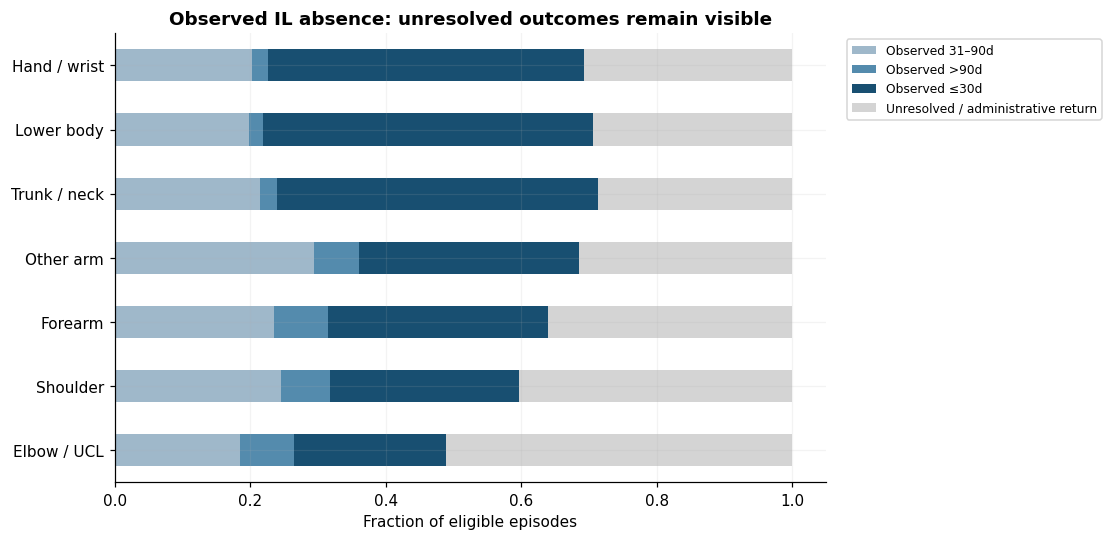

In [2]:
from src.injury_analysis.outcomes import severity_analysis
a, events, spec = load()
counts, summaries = severity_analysis(events)
display(counts)
display(read_table('severity_duration_groups'))
plots.severity_figure(); plt.show()

## Compare within anatomical categories
Duration groups are explicit observed-absence bins (≤30, 31–90, >90 days), not invented clinical severity. Unresolved/administrative returns form a separate group; no return is imputed and no Kaplan–Meier interpretation is asserted under informative missing activation. Surgery documentation may occur after injury and does not imply every undocumented case had no surgery. CIs use pitcher clusters and one pre-injury mean per event.

In [3]:
display(summaries[(summaries.comparison=='duration_group') & summaries.category.isin(['Elbow / UCL','Shoulder','Lower body']) & summaries.feature.eq('velo_z')])
display(summaries[(summaries.comparison=='surgery_documentation') & summaries.category.isin(['Elbow / UCL','Shoulder']) & summaries.feature.eq('velo_z')])
usable=int(counts.usable_durations.sum()); n=int(counts.events.sum())
conclusion(f"Only {usable:,}/{n:,} target-eligible episodes have usable activation-based durations for these comparisons. {n-usable:,} remain unresolved or have an administrative return. Observed-duration feature differences are therefore conditional descriptions, not evidence that longer biological recovery is more predictable; missing follow-up and category composition must remain visible.")

,category,comparison,subgroup,feature,mean,low,high,n,pitchers
0,Elbow / UCL,duration_group,Observed 31–90d,velo_z,-0.451201,-0.666159,-0.256706,90,85
4,Elbow / UCL,duration_group,Observed >90d,velo_z,-0.390950,-0.875266,-0.019925,27,27
8,Elbow / UCL,duration_group,Observed ≤30d,velo_z,-0.317435,-0.457788,-0.146637,132,121
12,Elbow / UCL,duration_group,Unresolved / administrative return,velo_z,-0.364115,-0.489909,-0.240208,198,187
48,Lower body,duration_group,Observed 31–90d,velo_z,-0.138007,-0.309404,0.039498,106,99
52,Lower body,duration_group,Observed >90d,velo_z,-0.386223,-1.130110,0.253142,11,11
56,Lower body,duration_group,Observed ≤30d,velo_z,-0.156519,-0.260881,-0.050037,321,247
60,Lower body,duration_group,Unresolved / administrative return,velo_z,-0.423235,-0.598565,-0.265218,162,152
80,Shoulder,duration_group,Observed 31–90d,velo_z,-0.475169,-0.643983,-0.315949,142,127
84,Shoulder,duration_group,Observed >90d,velo_z,-0.418965,-0.774256,-0.064489,32,32


,category,comparison,subgroup,feature,mean,low,high,n,pitchers
112,Elbow / UCL,surgery_documentation,Documented surgery,velo_z,-0.532335,-0.723778,-0.307577,95,94
116,Elbow / UCL,surgery_documentation,No surgery documentation,velo_z,-0.325534,-0.421406,-0.227490,352,286
152,Shoulder,surgery_documentation,Documented surgery,velo_z,-1.358320,-2.141727,-0.748940,7,7
156,Shoulder,surgery_documentation,No surgery documentation,velo_z,-0.486583,-0.569083,-0.397598,574,436


**Computed conclusion.** Only 2,252/3,552 target-eligible episodes have usable activation-based durations for these comparisons. 1,300 remain unresolved or have an administrative return. Observed-duration feature differences are therefore conditional descriptions, not evidence that longer biological recovery is more predictable; missing follow-up and category composition must remain visible.